<a href="https://colab.research.google.com/github/ronan-cunha/machine-learning-course/blob/main/Notebooks/aula_16_clustering_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import CountVectorizer
import re


# Base com data das votações
url_roll_calls = "https://raw.githubusercontent.com/rfordatascience/tidytuesday/master/data/2021/2021-03-23/roll_calls.csv"
df_roll = pd.read_csv(url_roll_calls)

In [3]:
print(df_roll.shape)
print(df_roll['rcid'].nunique())
df_roll.head(2)

(6202, 9)
6202


,rcid,session,importantvote,date,unres,amend,para,short,descr
0,3,1,0.0,1946-01-01,R/1/66,1.0,0.0,"AMENDMENTS, RULES OF PROCEDURE",TO ADOPT A CUBAN AMENDMENT TO THE UK PROPOSAL ...
1,4,1,0.0,1946-01-02,R/1/79,0.0,0.0,SECURITY COUNCIL ELECTIONS,TO ADOPT A USSR PROPOSAL ADJOURNING DEBATE ON ...


In [4]:
df_roll['year'] = pd.to_datetime(df_roll['date']).dt.year
df_roll.loc[2,'descr']

'TO ADOPT THE KOREAN PROPOSAL THAT INVALID BALLOTS BE INCLUDED IN THE TOTAL NUMBER OF \\MEMBERS PRESENT AND VOTING\\\\, IN CALCULATING THE MAJORITY VOTE.\\""'

In [5]:
df_roll_clean = df_roll[~df_roll['descr'].isna()]
df_roll_clean.shape

(6201, 10)

In [6]:
# 1. Passo TF (Term Frequency): Contagem simples de termos (Vetor esparso simples)
tf_vectorizer = CountVectorizer(stop_words='english', max_df=0.95, min_df=2)
X_tf = tf_vectorizer.fit_transform(df_roll_clean['descr'])

In [7]:
# Vamos pegar as palavras
terms = tf_vectorizer.get_feature_names_out()

# Criando DataFrames da mesma amostra (linhas 0 a 5)
df_tf_sample = pd.DataFrame(X_tf[:5].toarray(), columns=terms)

print("--- Matriz apenas com Frequência de Termos (TF) ---")
display(df_tf_sample.head())

--- Matriz apenas com Frequência de Termos (TF) ---


,000,04,06,07,08,09,10,100,101,102,...,youth,yrs,yugoslavia,zambia,zealand,zimbabwe,zimbabwese,zionism,zone,zones
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [8]:
# Remover números
df_roll_clean['descr_clean'] = df_roll_clean['descr'].str.replace(r'\d+', '', regex=True)

# Converter para minúsculo
df_roll_clean['descr_clean'] = df_roll_clean['descr_clean'].str.lower()

# Remover quebras de linha e barras invertidas
df_roll_clean['descr_clean'] = df_roll_clean['descr_clean'].str.replace('\\', ' ', regex=False).str.replace('\n', ' ', regex=False)

# Remover caracteres especiais e pontuação
df_roll_clean['descr_clean'] = df_roll_clean['descr_clean'].str.replace(r'[^a-zA-Z\s]', '', regex=True)

# Remover excesso de espaços em branco
df_roll_clean['descr_clean'] = df_roll_clean['descr_clean'].str.replace(r'\s+', ' ', regex=True).str.strip()

# Mostrar o resultado final
df_roll_clean['descr_clean'].head()

/tmp/ipykernel_638/2872818619.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_roll_clean['descr_clean'] = df_roll_clean['descr'].str.replace(r'\d+', '', regex=True)
/tmp/ipykernel_638/2872818619.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_roll_clean['descr_clean'] = df_roll_clean['descr_clean'].str.lower()
/tmp/ipykernel_638/2872818619.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

S

,descr_clean
0,to adopt a cuban amendment to the uk proposal ...
1,to adopt a ussr proposal adjourning debate on ...
2,to adopt the korean proposal that invalid ball...
3,to adopt a cuban proposal ac that an item on a...
4,to adopt a th committee amendment a to the pro...


In [9]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# Definir conjunto de stopwords padrão em inglês e adicionar palavras personalizadas
custom_stopwords = set(ENGLISH_STOP_WORDS)
custom_stopwords.update(['adopt', 'adopted', 'adopting',
                         'proposal', 'amendment', 'resolution'])

In [10]:
# Aplicar a remoção na coluna limpa
df_roll_clean['word'] = df_roll_clean['descr_clean'].str.split()
df_roll_clean['word'].head(2)

/tmp/ipykernel_638/2057286269.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_roll_clean['word'] = df_roll_clean['descr_clean'].str.split()


,word
0,"[to, adopt, a, cuban, amendment, to, the, uk, ..."
1,"[to, adopt, a, ussr, proposal, adjourning, deb..."


In [11]:
# Corrigindo a sintaxe para fazer a filtragem de stopwords
df_roll_clean['descr_clean'] = [
    " ".join([word for word in text if word not in custom_stopwords])
    for text in df_roll_clean['word']
]

# Exibir o resultado final limpo
df_roll_clean['descr_clean'].head()

/tmp/ipykernel_638/4095568504.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_roll_clean['descr_clean'] = [


,descr_clean
0,cuban uk referring provisional rules procedure...
1,ussr adjourning debate postponingelections non...
2,korean invalid ballots included total number m...
3,cuban ac item declaration rights duties man ta...
4,th committee provisional rules procedure provi...


In [12]:
# Filtrar e remover as stopwords (padrão e personalizadas) de cada linha sem usar funções adicionais
# Passando palavra por palavra para cada linha de texto da coluna descr_clean
df_roll_clean['descr_clean'] = [
    " ".join([word for word in str(text).split() if word not in custom_stopwords])
    for text in df_roll_clean['descr_clean']
]

# Visualizar amostra limpa final sem as stopwords
df_roll_clean['descr_clean'].head()

/tmp/ipykernel_638/446000860.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_roll_clean['descr_clean'] = [


,descr_clean
0,cuban uk referring provisional rules procedure...
1,ussr adjourning debate postponingelections non...
2,korean invalid ballots included total number m...
3,cuban ac item declaration rights duties man ta...
4,th committee provisional rules procedure provi...


In [13]:
# 1. Passo TF (Term Frequency): Contagem simples de termos (Vetor esparso simples)
tf_vectorizer = CountVectorizer(stop_words='english', max_df=0.95, min_df=2)
X_tf = tf_vectorizer.fit_transform(df_roll_clean['descr_clean'])

In [14]:
# Vamos pegar as palavras
terms = tf_vectorizer.get_feature_names_out()

# Criando DataFrames da mesma amostra (linhas 0 a 5)
df_tf_sample = pd.DataFrame(X_tf[:5].toarray(), columns=terms)

print("--- Matriz apenas com Frequência de Termos (TF) ---")
display(df_tf_sample.head())
print(X_tf.shape)

--- Matriz apenas com Frequência de Termos (TF) ---


,aa,aadd,ababa,abandon,abide,abkhazia,able,abolish,abolition,abroad,...,yrs,yugoslavia,zambia,zealand,zimbabwe,zimbabwese,zionism,zone,zones,zonesouthern
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


(6201, 3386)


In [16]:
from sklearn.cluster import KMeans
print("--- K-Means ---")
kmeans_a = KMeans(
    n_clusters=5,     # Número de clusters
    init='k-means++', #
    n_init=10,        # Executa o algoritmo 10 vezes com diferentes sementes e escolhe o melhor resultado
    max_iter=300,      # Número máximo de iterações por execução
    random_state=42
)
k_labels_a = kmeans_a.fit_predict(X_tf)
print(f"Inércia (Soma das distâncias quadráticas): {kmeans_a.inertia_:.2f}")

--- K-Means ---
Inércia (Soma das distâncias quadráticas): 85727.28


In [18]:
# Ajustando e aplicando o KMeans no vetor correto X_tf antes de imprimir
k_labels_a = kmeans_a.fit_predict(X_tf)
# Adicionar o rótulo de cluster da Configuração A ao DataFrame
df_roll_clean['cluster_km'] = k_labels_a

# mostrar os termos mais importantes de cada cluster
def print_top_terms(model, vectorizer, n_terms=5):
    order_centroids = model.cluster_centers_.argsort()[:, ::-1]
    terms = vectorizer.get_feature_names_out()
    for i in range(5):
        print(f"  Cluster {i+1}: ", end="")
        top_words = [terms[ind] for ind in order_centroids[i, :n_terms]]
        print(", ".join(top_words))

print("\nPalavras-chave por cluster (Configuração A):")
print_top_terms(kmeans_a, tf_vectorizer)


Palavras-chave por cluster (Configuração A):
  Cluster 1: draft, vote, paragraph, requested, president
  Cluster 2: general, assembly, rights, nuclear, states
  Cluster 3: draft, resol, paragraph, comm, committee
  Cluster 4: draft, assembly, committee, vote, president
  Cluster 5: vote, requested, president, paragraph, draft


/tmp/ipykernel_638/3639357132.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_roll_clean['cluster_km'] = k_labels_a


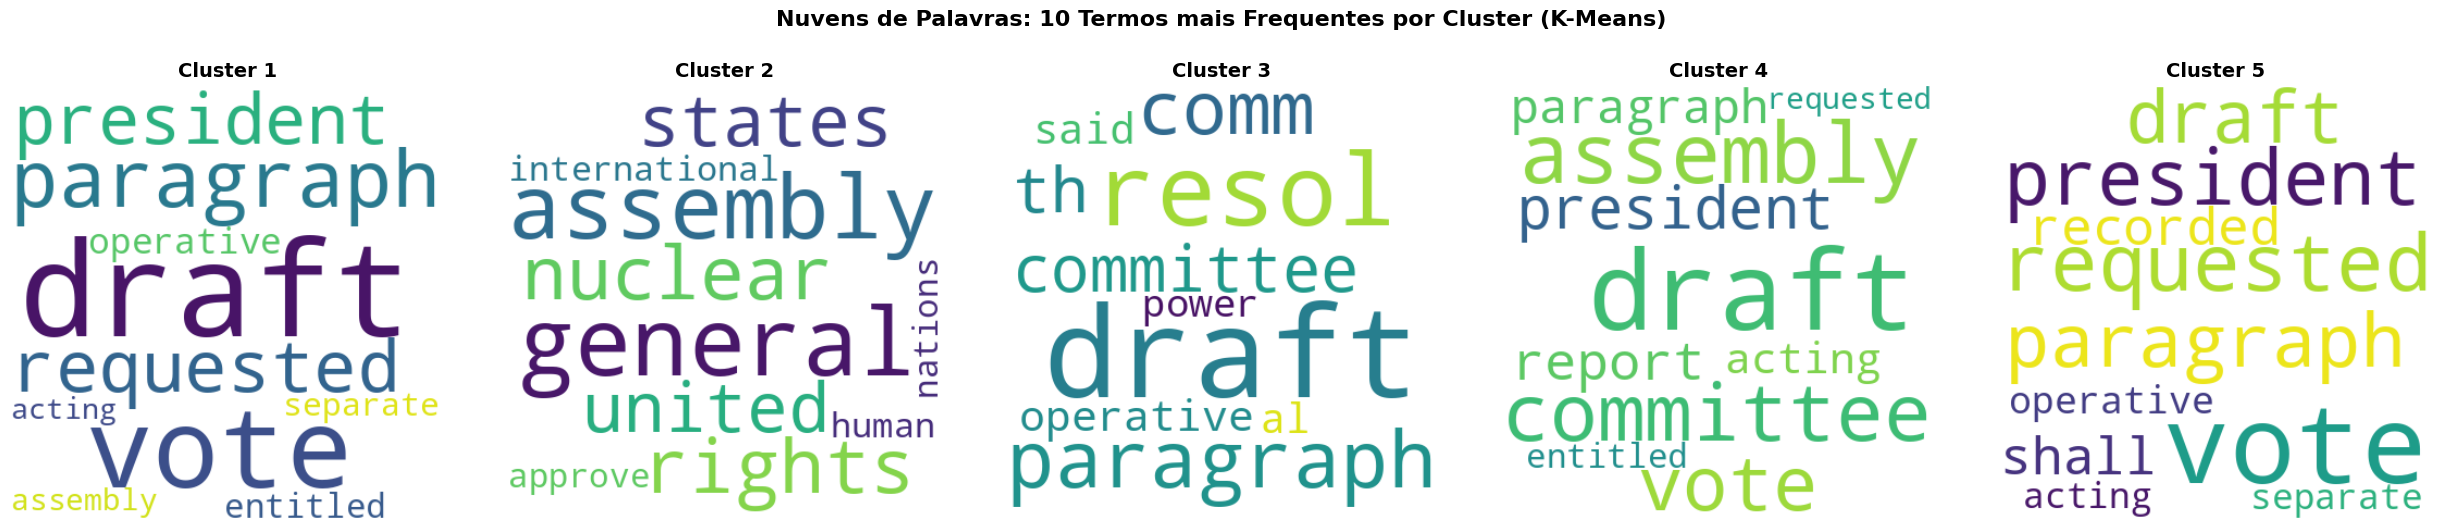

In [20]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt
from collections import Counter

# Definir os subplots (uma linha com 5 colunas ou conforme apropriado)
fig, axes = plt.subplots(1, 5, figsize=(25, 5))
fig.suptitle('Nuvens de Palavras: 10 Termos mais Frequentes por Cluster (K-Means)', fontsize=16, fontweight='bold', y=1.05)

for cluster_num in range(5):
    # Filtrar os textos pertencentes ao cluster atual
    textos_cluster = df_roll_clean[df_roll_clean['cluster_km'] == cluster_num]['descr_clean']

    # Unir e tokenizar as palavras para contar a frequência
    todas_palavras = " ".join(textos_cluster).split()

    # Pegar as 10 palavras mais frequentes
    contagem = Counter(todas_palavras)
    top_10 = dict(contagem.most_common(10))

    # Criar a nuvem de palavras baseada na frequência dos top 10 termos
    wordcloud = WordCloud(
        width=400,
        height=400,
        background_color='white',
        colormap='viridis'
    ).generate_from_frequencies(top_10)

    # Plotar o gráfico no respectivo subplot
    ax = axes[cluster_num]
    ax.imshow(wordcloud, interpolation='bilinear')
    ax.set_title(f'Cluster {cluster_num + 1}', fontsize=14, fontweight='bold')
    ax.axis('off')

plt.tight_layout()
plt.show()

### Explicação das Configurações do K-Means e seus Impactos

O comportamento do algoritmo K-Means é fortemente influenciado pelos seguintes hiperparâmetros:

1. **`init` (Método de Inicialização):**
   * **`k-means++`**: Seleciona os centroides iniciais de forma inteligente, posicionando-os distantes uns dos outros. Isso acelera significativamente a convergência e reduz a chance de o algoritmo ficar preso em mínimos locais ruins.
   * **`random`**: Escolhe observações aleatórias para servirem como centros iniciais. É mais rápido computacionalmente na largada, mas pode exigir mais iterações para convergir e gerar partições menos consistentes.

2. **`n_init` (Número de Inicializações):**
   * O K-Means é sensível à semente inicial. Definir um `n_init` alto (ex: 10) faz com que o algoritmo rode todo o processo de agrupamento várias vezes de forma independente, selecionando ao final a configuração com a menor inércia (melhor compactação). Reduzir este valor diminui o custo computacional, mas aumenta o risco de obtermos uma solução abaixo da ideal.

3. **`max_iter` (Máximo de Iterações):**
   * Define o limite de vezes que o algoritmo atualizará as coordenadas dos centroides em uma única execução. Se os clusters forem muito complexos e o limite for muito baixo (ex: 100), o algoritmo pode parar antes de atingir a convergência ideal.

# Atividade em aula

## 1. É possível identificar por esses cinco grupos os principais tópicos votados na ONU?
## 2. Como você ajustaria a estratégia de clusteriazação? Justifique.
## 3. Implemente e veja o resultado? Você faria outras alterações?